## Step 1-Load Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)    


In [4]:
#Load the data
df = pd.read_csv('../data/telco_comm_churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

## Basic Info

In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.shape

(7043, 21)

In [8]:
print("Missing values in each column:")
df.isnull().sum()

Missing values in each column:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
print("Target variable distribution:")
print(df['Churn'].value_counts())

Target variable distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [10]:
print(f"Churn Rate[Yes]:  {df['Churn'].value_counts(normalize=True)['Yes'] * 100:.2f}%")
print(f"Churn Rate[No]:  {df['Churn'].value_counts(normalize=True)['No'] * 100:.2f}%")

Churn Rate[Yes]:  26.54%
Churn Rate[No]:  73.46%


## Analyse Numerical Features

In [11]:
numerical_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
numerical_cols

['SeniorCitizen', 'tenure', 'MonthlyCharges']

In [12]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
numerical_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
numerical_cols

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

In [13]:
df[numerical_cols].describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


### Visualize Target Variable

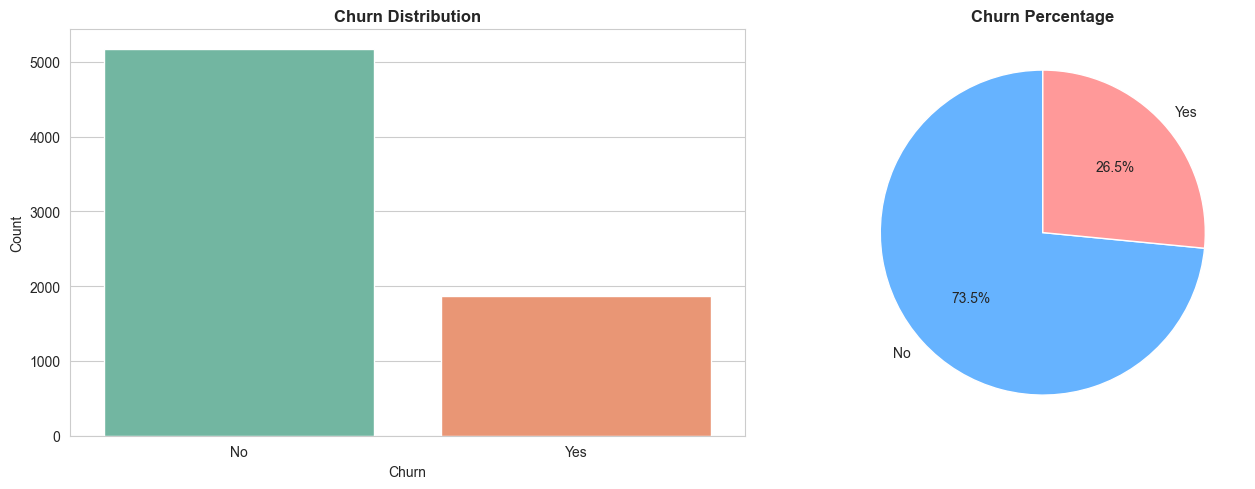

Saved: ../reports/churn_distribution.png


In [14]:
fig,ax = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x='Churn', palette='Set2', ax=ax[0])

ax[0].set_title('Churn Distribution', fontweight='bold')
churn_count = df['Churn'].value_counts()
ax[1].pie(churn_count, labels=churn_count.index, autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#ff9999'])
ax[1].set_title('Churn Percentage', fontweight='bold')
ax[0].set_ylabel('Count')


plt.tight_layout()


#save
plt.savefig('../reports/churn_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Saved: ../reports/churn_distribution.png")

### Numerical Features vs Churn

<Axes: xlabel='Churn', ylabel='TotalCharges'>

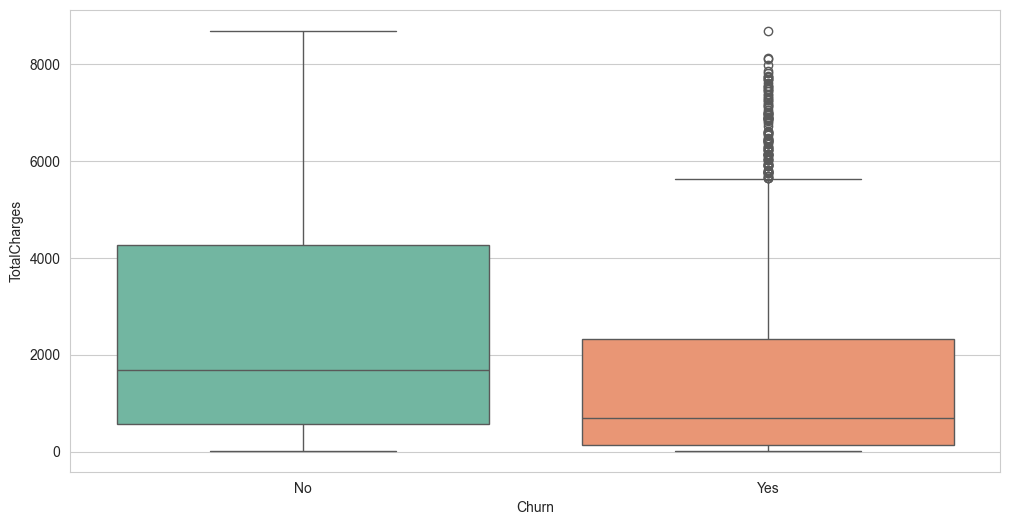

In [15]:
sns.boxplot(data=df, x='Churn', y='TotalCharges', palette='Set2')

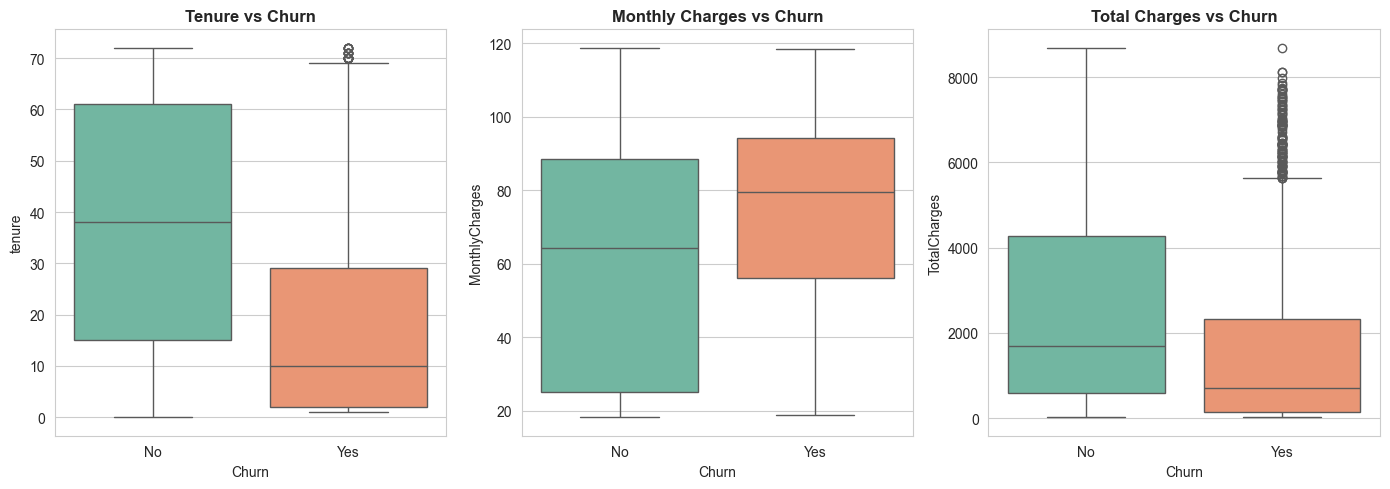

In [16]:
fig,ax = plt.subplots(1, 3, figsize=(14, 5))

#TODO: First Graph - Tenure
sns.boxplot(data = df, x='Churn', y='tenure', palette='Set2', ax=ax[0])
ax[0].set_title('Tenure vs Churn', fontweight='bold')

#TODO: Second Graph - MonthlyCharges
sns.boxplot(data = df, x='Churn', y='MonthlyCharges', palette='Set2', ax=ax[1])
ax[1].set_title('Monthly Charges vs Churn', fontweight='bold')

#TODO: THird Graph - TotalCharges
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
sns.boxplot(data = df, x='Churn', y='TotalCharges', palette='Set2', ax=ax[2])
ax[2].set_title('Total Charges vs Churn', fontweight='bold')

plt.tight_layout()


#save
plt.savefig('../reports/numerical_analysis.png', dpi=300, bbox_inches='tight')
plt.show()


## Analyse Categorical Features

In [17]:
categorical_cols=df.select_dtypes(include=['object']).columns.tolist()
categorical_cols

['customerID',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

In [18]:
categorical_cols.remove('customerID')
categorical_cols.remove('Churn')
categorical_cols

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [19]:
print(f"Categorical  Columns ({len(categorical_cols)}): {categorical_cols})")

Categorical  Columns (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod'])


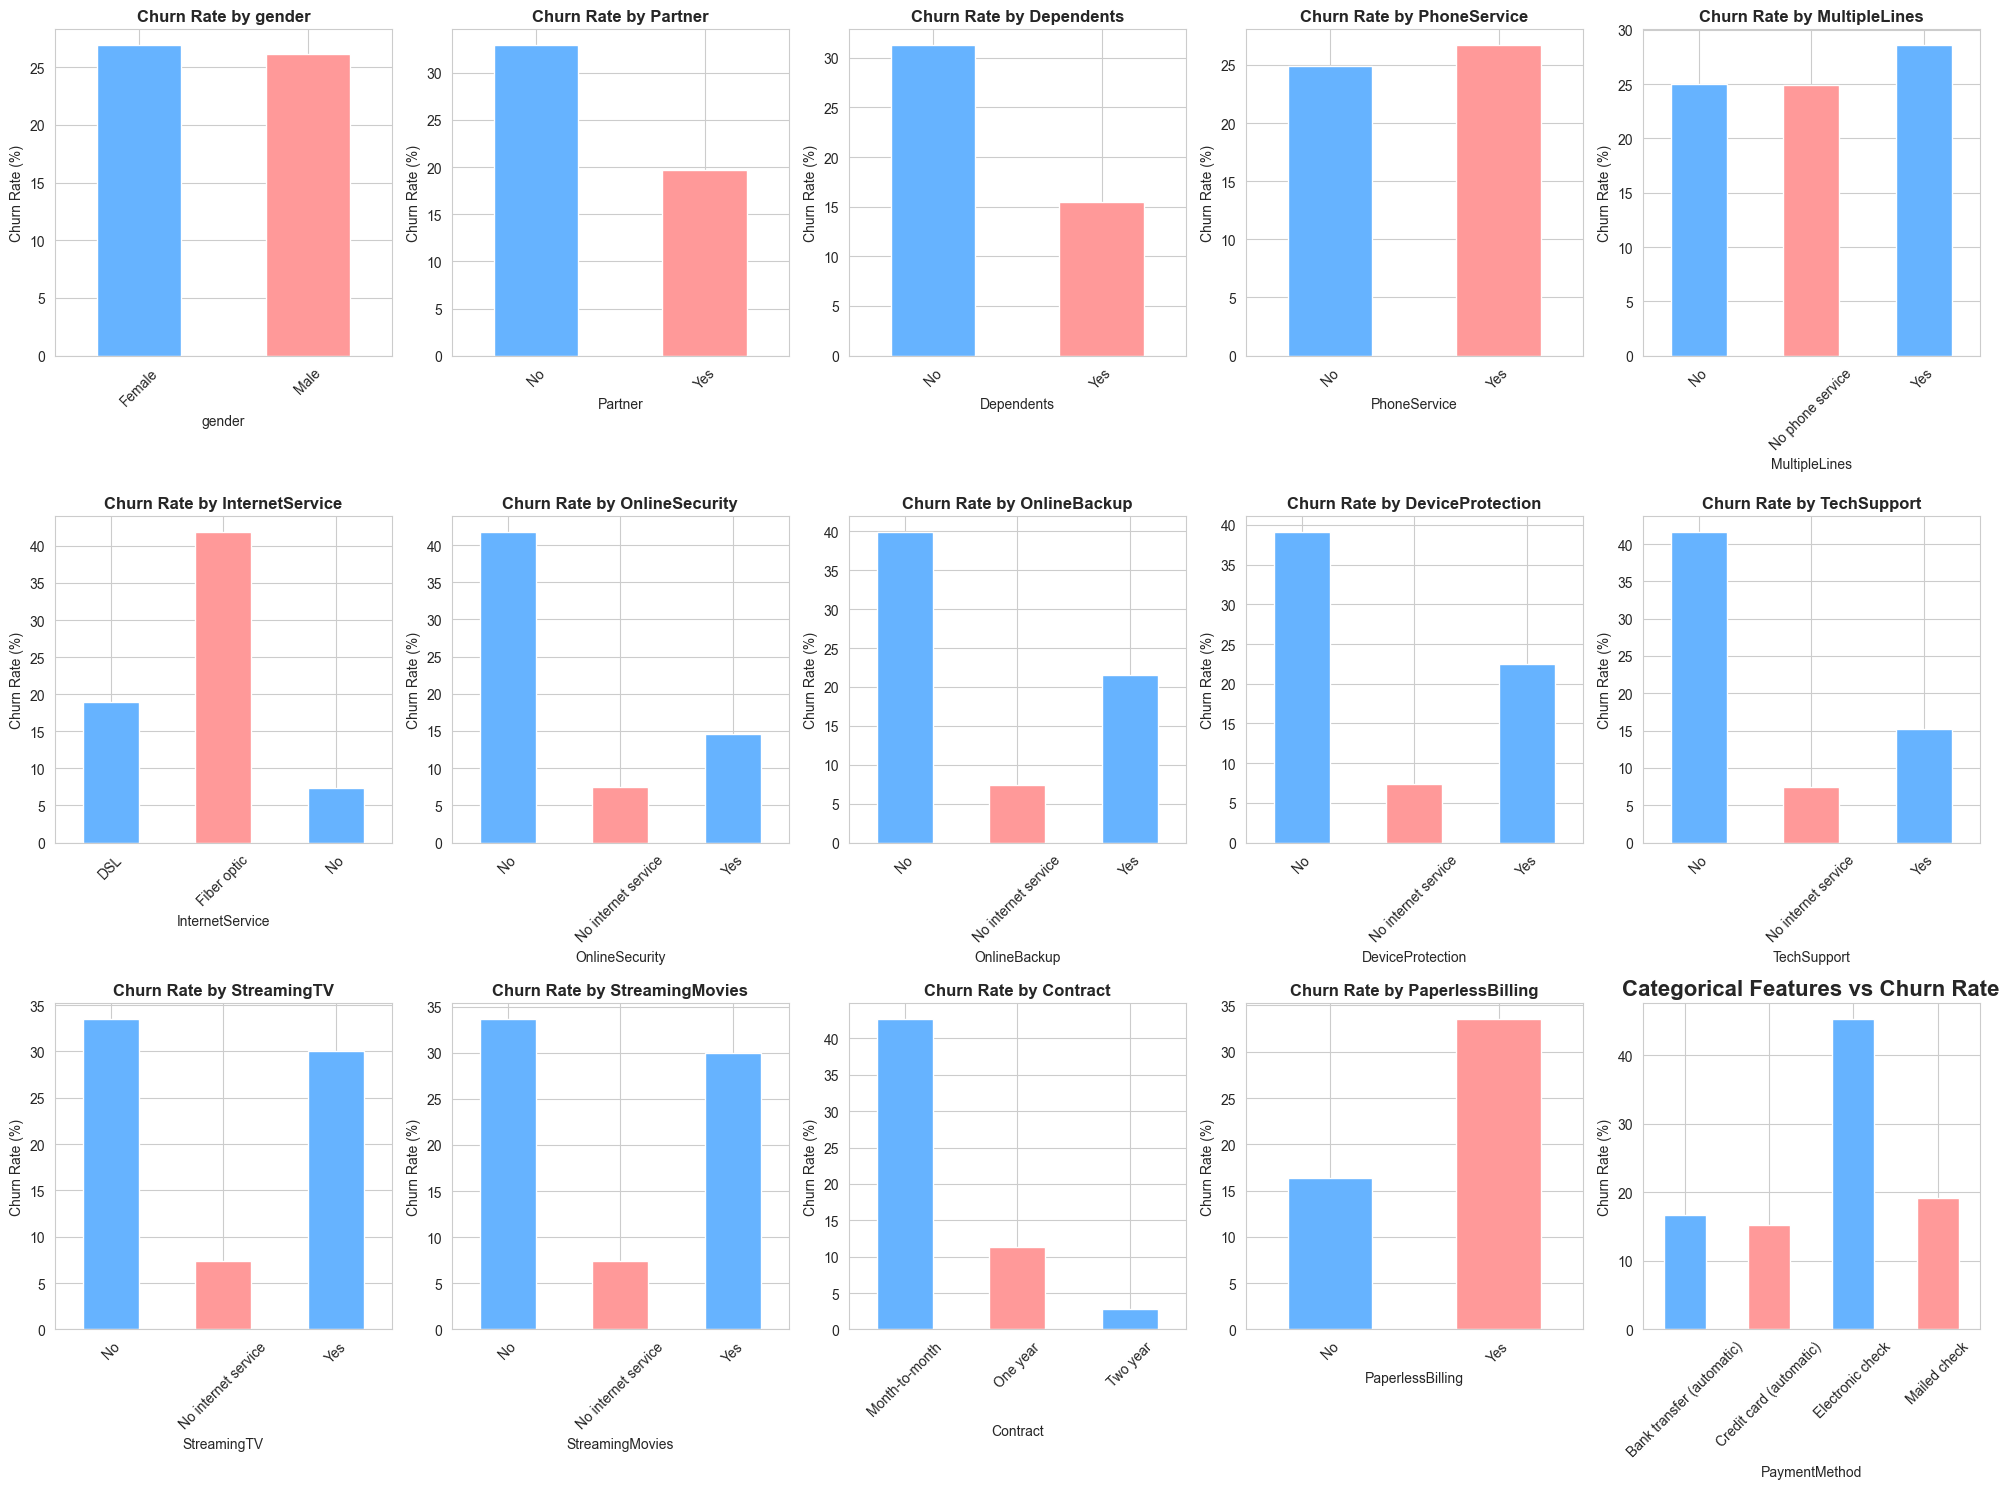

In [20]:

fig,ax = plt.subplots(3,5 , figsize=(20, 15))
ax = ax.flatten()


for idx,col in enumerate(categorical_cols):
    churn_rate = df.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').sum()/len(x)*100)
    churn_rate.plot(kind='bar', ax=ax[idx], color=['#66b3ff','#ff9999'])
    ax[idx].set_title(f'Churn Rate by {col}', fontweight='bold')
    ax[idx].set_ylabel('Churn Rate (%)')
    ax[idx].set_xlabel(col)
    ax[idx].tick_params(axis='x', rotation=45)

plt.title('Categorical Features vs Churn Rate', fontweight='bold', fontsize=16)
plt.tight_layout()

plt.savefig('../reports/categorical_analysis.png', dpi=300, bbox_inches='tight')
plt.show()    

In [21]:
df_corr = df.copy()
df_corr['Churn'] = df_corr['Churn'].map({'Yes': 1, 'No': 0})

In [22]:
numerical_features = ['tenure', 'MonthlyCharges', 'TotalCharges','Churn']

corr_matrix = df_corr[numerical_features].corr()
corr_matrix

,tenure,MonthlyCharges,TotalCharges,Churn
tenure,1.000000,0.247900,0.825880,-0.352229
MonthlyCharges,0.247900,1.000000,0.651065,0.193356
TotalCharges,0.825880,0.651065,1.000000,-0.199484
Churn,-0.352229,0.193356,-0.199484,1.000000


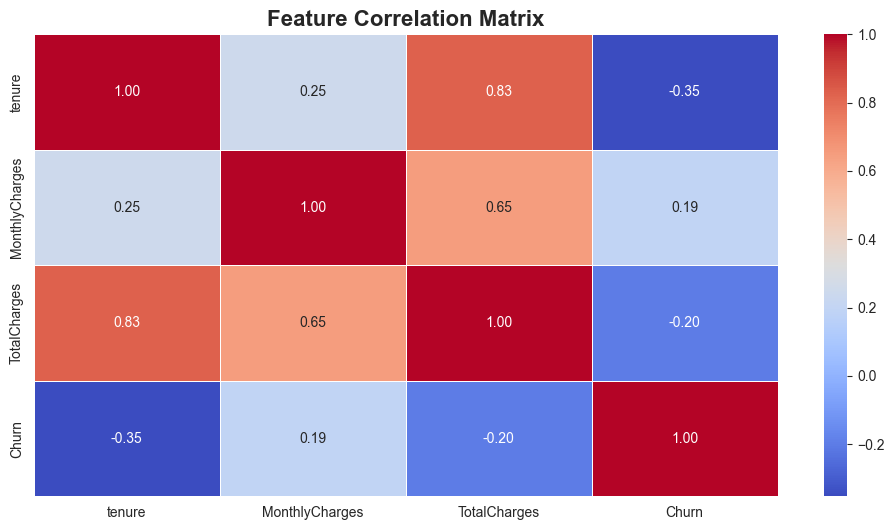

In [24]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Matrix', fontweight='bold', fontsize=16)
plt.savefig('../reports/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

NOTE : A multicollinearity between 'tenure' and 'TotalCharges'

In [44]:
print("="*60)
print("Key Insights from EDA")
print("="*60)

print(f"\n1. Dataset size : {df.shape[0]} customers, {df.shape[1]} features")
print(f"2. Churn rate: {(df['Churn']=='Yes').sum()/len(df)*100:.2f}%")
print(f"3. Missing values in the dataset: {df.isnull().sum().sum()} total")

avg_tenure_churn = df[df['Churn'] == 'Yes']['tenure'].mean()
avg_tenure_no_churn = df[df['Churn'] == 'No']['tenure'].mean()
print(f"4. Average tenure for churned customers: {avg_tenure_churn:.1f} months")
print(f"5. Average tenure for non-churned customers: {avg_tenure_no_churn:.1f} months")

avg_monthly_churn = df[df['Churn'] == 'Yes']['MonthlyCharges'].mean()
avg_monthly_no_churn = df[df['Churn'] == 'No']['MonthlyCharges'].mean()
print(f"6. Average monthly charges for churned customers: ${avg_monthly_churn:.1f}")
print(f"7. Average monthly charges for non-churned customers: ${avg_monthly_no_churn:.2f}")

print("="*60)
print("A holistic analysis reveals that short-term, high-cost digital \n services(Fibre Optic/Electronic Clocks) are the primary churn \n drivers, while long-term tenure and value-added security \n services are the strongest indicatores of customer loyalty.")
print("="*60)

print("="*60)
print(" EDA COMPLETED")
print("="*60)

Key Insights from EDA

1. Dataset size : 7043 customers, 21 features
2. Churn rate: 26.54%
3. Missing values in the dataset: 11 total
4. Average tenure for churned customers: 18.0 months
5. Average tenure for non-churned customers: 37.6 months
6. Average monthly charges for churned customers: $74.4
7. Average monthly charges for non-churned customers: $61.27
A holistic analysis reveals that short-term, high-cost digital 
 services(Fibre Optic/Electronic Clocks) are the primary churn 
 drivers, while long-term tenure and value-added security 
 services are the strongest indicatores of customer loyalty.
 EDA COMPLETED
